# Phase 1: Legal Language Model Pre-training - Legal-GraphProp

## Task
Train a legal language model from scratch. Given a 512-word prompt from a legal document, the model writes the next 128 words. Scored with BERTScore F1 (main) and ROUGE-L F1.

Author: Preet Patel (261110043)

Model: no attention. Each token is a node linked to its last W tokens; a small gated network scores each edge and messages from neighbours are summed over several rounds, like a graph neural network. About 269M parameters (dim 1536, 8 layers, window 24), pre-layer-norm and tied embeddings. Because each layer sees only a fixed window, generation only needs to feed the recent tokens.

## Input
- Phase-1 legal text from the Hugging Face dataset (needs the HF_TOKEN secret): up to 6,000 documents per source, 24,000 in total.
- Official Phase-1 test prompts.

## Flow of the notebook (from input to output)
1. Set up the environment and memory helpers.
2. Set the training settings and output folders.
3. Log in and find the data files.
4. Stream the legal documents piece by piece with low memory and remove very noisy ones.
5. Load the official test prompts.
6. Train a byte-level BPE tokenizer from scratch on the legal text.
7. Build the GraphProp model and check its parameter count.
8. Define the train / validation split functions.
9. Define the dataset, the training loop (warm-up + cosine learning rate, gradient accumulation, mixed precision, label smoothing) and the evaluation.
10. Create the 90/10 random train / validation split.
11. Run a quick speed and memory test.
12. Train for 20,000 updates while checking validation loss, then score the model on validation prompts.
13. Plot training vs validation loss to check overfitting.
14. Save the model and its score record.
15. Generate continuations for the test prompts and package them.

## Output
- Model checkpoint (.pt), tokenizer (.json) and score record.
- Training vs validation loss plot.
- submission.zip with the test continuations.

In [1]:
# Environment setup and memory helper functions
import os, json, gc, ctypes, random, zipfile, resource
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

N_PHASES = 13
# It takes n (number) and msg (message) as input, prints which step of the notebook is running and returns nothing.
def phase_marker(n, msg):
    print(f"\n[GraphProp | {n}/{N_PHASES}] {msg}")

# It returns how much RAM this process is using (GB).
def host_ram_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1024 ** 2)

# It takes tag (label) as input, prints the current RAM usage with a label and returns nothing.
def log_ram(tag):
    print(f"    (ram) {tag}: {host_ram_gb():.2f} GB")

# It frees unused CPU and GPU memory and returns nothing.
def release_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass

# It takes net (model) and purpose (what it is for) as input, uses all available GPUs if there is more than one and returns the model, wrapped for several GPUs if available.
def enable_multi_gpu(net, purpose=None):
    use_dp = True
    if purpose is not None:
        use_dp = getattr(globals().get("Settings"), "DP_CHOICE", {}).get(purpose, True)
    if use_dp and torch.cuda.is_available() and torch.cuda.device_count() > 1:
        print(f"    multi-GPU: using {torch.cuda.device_count()} GPUs via nn.DataParallel"
              + (f" (for {purpose})" if purpose else ""))
        return nn.DataParallel(net)
    if purpose is not None and torch.cuda.is_available() and torch.cuda.device_count() > 1:
        print(f"    multi-GPU: benchmark found one GPU faster/safer for {purpose} -> NOT using DataParallel")
    return net

# It takes net (model) as input, gets the plain model back from the multi-GPU wrapper and returns the plain model.
def strip_replica(net):
    return net.module if isinstance(net, nn.DataParallel) else net

phase_marker(1, "Environment ready")
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
torch.backends.cudnn.benchmark = True
print(f"device = {device}")
if device.type == "mps":
    print("note: Apple GPU (MPS) selected -- unified memory is shared with system RAM, "
          "so watch Settings.BATCH_SIZE/MODEL_DIM below if you see slowdowns from memory "
          "pressure rather than a hard OOM crash (there is no MPS equivalent of CUDA's "
          "hard VRAM ceiling).")
if torch.cuda.is_available():
    print(f"gpu    = {torch.cuda.get_device_name(0)}")
    print(f"vram   = {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    if torch.cuda.device_count() > 1:
        print(f"note: {torch.cuda.device_count()} GPUs detected -- consider raising "
              f"Settings.BATCH_SIZE / Settings.GEN_BATCH_SIZE (roughly x{torch.cuda.device_count()}) "
              f"below so each GPU gets a full batch.")
log_ram("after setup")


[GraphProp | 1/13] Environment ready
device = cuda
gpu    = Tesla T4
vram   = 15.6 GB
note: 2 GPUs detected -- consider raising Settings.BATCH_SIZE / Settings.GEN_BATCH_SIZE (roughly x2) below so each GPU gets a full batch.
    (ram) after setup: 0.56 GB


In [2]:
# Set training settings and output folders
phase_marker(2, "Preparing run settings + output folders")
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle") else os.path.join(os.getcwd(), "kaggle_working")
CKPT_DIR = os.path.join(WORK_DIR, "checkpoints")
OUT_DIR = os.path.join(WORK_DIR, "outputs")
for d in (CKPT_DIR, OUT_DIR):
    Path(d).mkdir(parents=True, exist_ok=True)

class Settings:
    PROMPT_TOKENS = 512
    CONT_TOKENS = 128
    SEQ_TOKENS = PROMPT_TOKENS + CONT_TOKENS
    VOCAB_SIZE = 12000
    BPE_TRAIN_SAMPLE_DOCS = 10000
    BPE_TRAIN_CHARS_PER_DOC = 3000

    DOCS_PER_SOURCE_CAP = 6000
    TOTAL_DOCS_CAP = 24000

    MODEL_DIM = 1536
    MODEL_LAYERS = 8
    MODEL_WINDOW = 24
    MODEL_EDGE_DIM = 112
    TIE_EMBEDDINGS = True

    BATCH_SIZE = 8
    GRAD_ACCUM_STEPS = 2
    PEAK_LR = 3e-4
    WARMUP_FRAC = 0.06
    MIN_LR_FRAC = 0.10
    WEIGHT_DECAY = 0.05
    GRAD_CLIP = 1.0
    SEED = 7

    DROPOUT = 0.2
    LABEL_SMOOTHING = 0.1

    EVAL_EVERY = 100
    EARLY_STOP_MIN_DELTA = 0.005
    VAL_LOSS_SAMPLE = 500

    STEPS_THIS_SPLIT = 20000

    SMOKE_TEST = False
    if SMOKE_TEST:
        STEPS_THIS_SPLIT = 300
        EVAL_EVERY = 100
        _SMOKE_GEN_CAP = 20

    RESUME_CHECKPOINT_PATH = None
    RESUME_TOKENIZER_PATH = None

    NOISE_DOC_MAX = 0.5

    GEN_MIN_CHARS = 20
    GEN_MIN_LEN_RETRIES = 3

    RECEPTIVE_FIELD = MODEL_LAYERS * (MODEL_WINDOW - 1) + 1
    GEN_BATCH_SIZE = 32
    LOADER_WORKERS = 3
    DP_CHOICE = {}

    REPETITION_PENALTY = 1.3

random.seed(Settings.SEED); np.random.seed(Settings.SEED); torch.manual_seed(Settings.SEED)
print(f"sequence length = {Settings.SEQ_TOKENS} tokens (prompt {Settings.PROMPT_TOKENS} + continuation {Settings.CONT_TOKENS})")
print(f"data budget: up to {Settings.DOCS_PER_SOURCE_CAP} docs/source, {Settings.TOTAL_DOCS_CAP} docs total")
print(f"model: dim={Settings.MODEL_DIM} layers={Settings.MODEL_LAYERS} window={Settings.MODEL_WINDOW} "
      f"tied_embeddings={Settings.TIE_EMBEDDINGS} (exact parameter count printed in PHASE 7)")
print(f"generation context bound (receptive field) = {Settings.RECEPTIVE_FIELD} tokens "
      f"(vs. the full {Settings.SEQ_TOKENS}-token sequence -- this is the KV-cache substitute, see PHASE 9)")
print(f"optimizer updates for this split = {Settings.STEPS_THIS_SPLIT} "
      f"(physical batch {Settings.BATCH_SIZE} x grad-accum {Settings.GRAD_ACCUM_STEPS} = "
      f"effective batch {Settings.BATCH_SIZE * Settings.GRAD_ACCUM_STEPS}), "
      f"early stopping DISABLED")
print(f"LR schedule: linear warmup ({Settings.WARMUP_FRAC:.0%} of steps) -> cosine decay to {Settings.MIN_LR_FRAC:.0%} of peak LR")
print(f"regularization: dropout={Settings.DROPOUT}, weight_decay={Settings.WEIGHT_DECAY}")
print("\n" + "=" * 78)
if Settings.SMOKE_TEST:
    print(f"SMOKE_TEST = True -- running the FULL real pipeline (same corpus, model size, batch "
          f"shape, AMP) at STEPS_THIS_SPLIT={Settings.STEPS_THIS_SPLIT} (vs the real full-length "
          f"run) and capped official generation ({Settings._SMOKE_GEN_CAP} prompts), ~30 min total.")
    print("Run this once. If it completes cleanly with no CUDA OOM, set Settings.SMOKE_TEST = False "
          "and re-run for the real full-length training.")
    print("A clean smoke-test pass is a strong (not 100%) signal the full run will not OOM, since "
          "batch shapes and every memory-relevant setting are identical -- only step COUNT differs.")
else:
    print(f"SMOKE_TEST = False -- running the REAL full configuration: STEPS_THIS_SPLIT="
          f"{Settings.STEPS_THIS_SPLIT}, full corpus, full official test set generation. The "
          f"OOM-retry-and-halve safety net (PHASE 8) is the last line of defense if this still "
          f"hits a CUDA OOM.")
print("=" * 78)
print("NOTE: this run is tuned for quality over speed -- expect this to take substantially "
      "longer than a quick smoke-test run, plausibly many hours end to end (outside SMOKE_TEST). "
      "CELL 10's benchmark gives a real ETA (and peak GPU memory) on your hardware before CELL 11 "
      "commits to the full run; lower Settings.MODEL_DIM/MODEL_LAYERS or Settings.BATCH_SIZE above "
      "if that memory reading is too close to your GPU's limit.")


[GraphProp | 2/13] Preparing run settings + output folders
sequence length = 640 tokens (prompt 512 + continuation 128)
data budget: up to 6000 docs/source, 24000 docs total
model: dim=1536 layers=8 window=24 tied_embeddings=True (exact parameter count printed in PHASE 7)
generation context bound (receptive field) = 185 tokens (vs. the full 640-token sequence -- this is the KV-cache substitute, see PHASE 9)
optimizer updates for this split = 20000 (physical batch 8 x grad-accum 2 = effective batch 16), early stopping DISABLED
LR schedule: linear warmup (6% of steps) -> cosine decay to 10% of peak LR
regularization: dropout=0.2, weight_decay=0.05

SMOKE_TEST = False -- running the REAL full configuration: STEPS_THIS_SPLIT=20000, full corpus, full official test set generation. The OOM-retry-and-halve safety net (PHASE 8) is the last line of defense if this still hits a CUDA OOM.
NOTE: this run is tuned for quality over speed -- expect this to take substantially longer than a quick smoke

In [3]:
# Log in to Hugging Face and find the data files
import subprocess, sys
phase_marker(3, "Resolving auth + data source URLs")
log_ram("start")

try:
    import ijson
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ijson"])
    import ijson
import requests
from huggingface_hub import login
from datasets import load_dataset

# It finds the Hugging Face login token and returns the token string.
def get_auth_token():
    try:
        from kaggle_secrets import UserSecretsClient
        tok = UserSecretsClient().get_secret("HF_TOKEN")
        if tok:
            print("auth: using Kaggle Secrets HF_TOKEN")
            return tok
    except Exception:
        pass
    try:
        from google.colab import userdata
        tok = userdata.get("HF_TOKEN")
        if tok:
            print("auth: using Colab Secrets HF_TOKEN")
            return tok
    except Exception:
        pass
    tok = os.environ.get("HF_TOKEN", "")
    if tok:
        print("auth: using HF_TOKEN env var")
        return tok
    try:
        import getpass
        return getpass.getpass("Enter your Hugging Face token (hidden; this dataset is gated): ")
    except Exception:
        return ""

auth_token = get_auth_token()
if not auth_token:
    print("WARNING: no HF token found -- the dataset is gated, every load below will fail.")
    print("Get one at https://huggingface.co/settings/tokens and request access to")
    print("https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone, then re-run.")
else:
    try:
        login(token=auth_token, add_to_git_credential=False)
        print("auth: authenticated with the Hub")
    except Exception as e:
        print(f"auth warning: {e}")

REPO_ID = "Exploration-Lab/CS-781-Capstone"
SRC_FILES = {
    "acts": "Phase_1_Pretraining/Train/train_acts.json",
    "high_courts": "Phase_1_Pretraining/Train/train_high_courts.json",
    "supreme_court": "Phase_1_Pretraining/Train/train_supreme_court.json",
    "tribunals": "Phase_1_Pretraining/Train/train_tribunals.json",
}
SRC_URLS = {name: f"https://huggingface.co/datasets/{REPO_ID}/resolve/main/{path}"
            for name, path in SRC_FILES.items()}
for name, url in SRC_URLS.items():
    print(f"  source[{name}] -> {url}")

print("\nOpening the official test stream (small file -- ordinary streaming is fine here)...")
try:
    official_test_stream = load_dataset(REPO_ID, name="phase_1", split="test", streaming=True,
                                         token=auth_token if auth_token else None)
    print("test stream: opened")
except Exception as e:
    print(f"test stream unavailable: {e}")
    official_test_stream = None
log_ram("end")


[GraphProp | 3/13] Resolving auth + data source URLs
    (ram) start: 0.57 GB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 1.5 MB/s eta 0:00:00
auth: using Kaggle Secrets HF_TOKEN
auth: authenticated with the Hub
  source[acts] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_acts.json
  source[high_courts] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_high_courts.json
  source[supreme_court] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_supreme_court.json
  source[tribunals] -> https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone/resolve/main/Phase_1_Pretraining/Train/train_tribunals.json

Opening the official test stream (small file -- ordinary streaming is fine here)...


README.md:   0%|          | 0.00/16.1k [00:00<?, ?B/s]

test stream: opened
    (ram) end: 0.73 GB


In [4]:
# Build the training corpus (download legal documents)
phase_marker(4, "Building training corpus")
log_ram("start")

corpus = []
DOC_CHAR_CAP = 6000

# It takes text as input, gives a document a noise score from 0 to 1 (higher means messier text) and returns a number from 0 (clean) to 1 (noisy).
def doc_noise_score(text):
    if not text:
        return 1.0
    n = len(text)
    standard = sum(1 for c in text if c.isalnum() or c.isspace() or c in ".,;:\'\"()-/%&")
    nonstandard_ratio = 1 - (standard / n)
    run_chars, i = 0, 0
    while i < n:
        j = i
        while j < n and text[j] == text[i]:
            j += 1
        if j - i >= 8:
            run_chars += (j - i)
        i = j
    run_ratio = run_chars / n
    words = text.split()
    if words:
        bad = sum(1 for w in words if len(w) > 25 or not any(c.isalpha() for c in w))
        fragment_ratio = bad / len(words)
    else:
        fragment_ratio = 1.0
    return min(1.0, (nonstandard_ratio + run_ratio + fragment_ratio) / 3)

# It takes url (file URL), token (login token), cap (maximum value), label (name to print) and retries (number of retries) as input, downloads a big JSON file piece by piece and keeps up to a limit of documents and returns a number of documents kept (None if it failed).
def stream_array_capped(url, token, cap, label, retries=8):
    import time as _t
    headers = {"Authorization": f"Bearer {token}"} if token else {}
    noise_max = getattr(Settings, "NOISE_DOC_MAX", 1.0)
    got, rejected_noisy, seen_items = 0, 0, 0
    for attempt in range(1, retries + 1):
        try:
            skip = seen_items
            if skip:
                print(f"    {label}: resuming on a fresh connection -- fast-forwarding past {skip:,} consumed elements...")
            with requests.get(url, headers=headers, stream=True, timeout=180) as resp:
                resp.raise_for_status()
                pos = 0
                for item in ijson.items(resp.raw, "item"):
                    pos += 1
                    if pos <= skip:
                        continue
                    seen_items = pos
                    text = item.get("text", "") if isinstance(item, dict) else ""
                    if not (text and len(text) > 100):
                        continue
                    text = text[:DOC_CHAR_CAP]
                    if doc_noise_score(text) > noise_max:
                        rejected_noisy += 1
                        continue
                    corpus.append({"text": text, "source": label})
                    got += 1
                    if got % 200 == 0:
                        release_memory()
                        print(f"    {label}: {got} docs ({rejected_noisy} rejected so far for noise > {noise_max})")
                    if got >= cap:
                        break
            break
        except Exception as e:
            if got >= cap:
                break
            print(f"    {label}: stream error {type(e).__name__} ({e}) at {got}/{cap} docs -- attempt {attempt}/{retries}")
            if attempt < retries:
                wait = min(15 * attempt, 90)
                print(f"    {label}: retrying on a fresh connection in {wait}s...")
                _t.sleep(wait)
            else:
                print(f"    {label}: giving up after {retries} attempts with {got} docs collected -- "
                      + ("keeping them and moving on." if got else "nothing collected, trying the datasets library."))
                return None if got == 0 else got
    if rejected_noisy:
        print(f"    {label}: {rejected_noisy} candidate document(s) rejected outright for doc_noise_score > {noise_max}")
    return got

# It takes stream (data stream), label (name to print) and cap (maximum value) as input, returns a number of documents collected; it is the backup way to collect documents if streaming fails.
def fallback_collect(stream, label, cap):
    noise_max = getattr(Settings, "NOISE_DOC_MAX", 1.0)
    n = 0
    for item in stream:
        text = item.get("text", "")
        if not (text and len(text) > 100):
            continue
        text = text[:DOC_CHAR_CAP]
        if doc_noise_score(text) > noise_max:
            continue
        corpus.append({"text": text, "source": label})
        n += 1
        if n % 200 == 0:
            release_memory()
        if n >= cap:
            break
    return n

any_ok = False
for name, url in SRC_URLS.items():
    print(f"streaming '{name}' (cap {Settings.DOCS_PER_SOURCE_CAP})...")
    n = stream_array_capped(url, auth_token, Settings.DOCS_PER_SOURCE_CAP, name)
    if n is None:
        print(f"  falling back to datasets library for '{name}'...")
        try:
            ds = load_dataset(REPO_ID, data_files=SRC_FILES[name], split="train", streaming=True,
                               token=auth_token if auth_token else None)
            n = fallback_collect(ds, name, Settings.DOCS_PER_SOURCE_CAP)
        except Exception as e:
            print(f"  fallback also failed: {e}")
            n = 0
    print(f"  -> {n or 0} docs from {name}")
    any_ok = any_ok or bool(n)
    if len(corpus) >= Settings.TOTAL_DOCS_CAP:
        break

if not any_ok:
    print("all per-source loading failed -- falling back to the merged 'train' split.")
    merged = load_dataset(REPO_ID, name="phase_1", split="train", streaming=True,
                           token=auth_token if auth_token else None)
    fallback_collect(merged, "mixed", Settings.TOTAL_DOCS_CAP)

corpus = corpus[:Settings.TOTAL_DOCS_CAP]
release_memory()
source_counts = Counter(d["source"] for d in corpus)
print(f"\ncorpus size = {len(corpus)} docs; by source: {dict(source_counts)}")
log_ram("end")


[GraphProp | 4/13] Building training corpus
    (ram) start: 0.73 GB
streaming 'acts' (cap 6000)...
    acts: 200 docs (0 rejected so far for noise > 0.5)
    acts: 400 docs (0 rejected so far for noise > 0.5)
    acts: 600 docs (0 rejected so far for noise > 0.5)
    acts: 800 docs (0 rejected so far for noise > 0.5)
    acts: 1000 docs (0 rejected so far for noise > 0.5)
    acts: 1200 docs (0 rejected so far for noise > 0.5)
    acts: 1400 docs (0 rejected so far for noise > 0.5)
    acts: 1600 docs (0 rejected so far for noise > 0.5)
    acts: 1800 docs (0 rejected so far for noise > 0.5)
    acts: 2000 docs (0 rejected so far for noise > 0.5)
    acts: 2200 docs (0 rejected so far for noise > 0.5)
    acts: 2400 docs (0 rejected so far for noise > 0.5)
    acts: 2600 docs (0 rejected so far for noise > 0.5)
    acts: 2800 docs (0 rejected so far for noise > 0.5)
    acts: 3000 docs (0 rejected so far for noise > 0.5)
    acts: 3200 docs (0 rejected so far for noise > 0.5)
    act

In [5]:
# Load the official test prompts
phase_marker(5, "Collecting official test prompts")
official_ids, official_prompts = [], []
PROMPT_FIELDS = ["text", "prompt", "input", "input_text", "document", "context", "source"]

# It takes d (one test record) as input, gets the prompt text from one test record and returns prompt text (empty if missing).
def pull_prompt(d):
    for k in PROMPT_FIELDS:
        v = d.get(k) if isinstance(d, dict) else None
        if v:
            return v
    return ""

# It takes keys as input, checks whether the record keys are just numbers and returns True or False.
def is_flattened(keys):
    if not keys:
        return False
    digit_like = sum(1 for k in keys if str(k).lstrip("-").isdigit())
    return digit_like / len(keys) > 0.9

if official_test_stream:
    try:
        first = next(iter(official_test_stream))
        print(f"first row: {len(first)} keys, sample {list(first.keys())[:10]}")
    except StopIteration:
        first = None
        print("test stream produced zero rows")

    if first is not None and is_flattened(first.keys()):
        print("flattened format detected: row keys are IDs, values are prompts")
        for tid, val in first.items():
            p = pull_prompt(val) if isinstance(val, dict) else (val if isinstance(val, str) else "")
            if p:
                official_ids.append(str(tid))
                official_prompts.append(p)
    elif first is not None:
        try:
            official_test_stream = load_dataset(REPO_ID, name="phase_1", split="test", streaming=True,
                                                  token=auth_token if auth_token else None)
        except Exception as e:
            print(f"could not reopen test stream: {e}")
        for item in official_test_stream:
            p = pull_prompt(item)
            tid = str(item.get("id", len(official_ids)))
            if p:
                official_ids.append(tid)
                official_prompts.append(p)
    print(f"collected {len(official_prompts)} test prompts")
else:
    print("no test stream available")
log_ram("end")


[GraphProp | 5/13] Collecting official test prompts
first row: 1000 keys, sample ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
flattened format detected: row keys are IDs, values are prompts
collected 1000 test prompts
    (ram) end: 0.83 GB


In [6]:
# Train our own tokenizer on the legal text
import re as _re
from collections import defaultdict as _defaultdict

phase_marker(6, "Training tokenizer (from-scratch byte-level BPE on this project's own corpus)")

# It maps every byte to a printable character for the byte-level tokenizer and returns a dictionary from byte value to character.
def _bytes_to_unicode():
    bs = list(range(ord("!"), ord("~") + 1)) + list(range(ord("\xa1"), ord("\xac") + 1)) + \
         list(range(ord("\xae"), ord("\xff") + 1))
    cs = bs[:]
    n = 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return dict(zip(bs, [chr(c) for c in cs]))

_BYTE_ENCODER = _bytes_to_unicode()
_BYTE_DECODER = {v: k for k, v in _BYTE_ENCODER.items()}
_PRETOK_RE = _re.compile(r"\'s|\'t|\'re|\'ve|\'m|\'ll|\'d| ?[A-Za-z]+| ?[0-9]+| ?[^\sA-Za-z0-9]+|\s+")

class LegalByteBPETokenizer:

    PAD_TOKEN = "<pad>"
    EOS_TOKEN = "<|endoftext|>"

    # It creates an empty tokenizer and returns nothing.
    def __init__(self):
        self.vocab = {}
        self.id_to_token = {}
        self.merge_rank = {}
        self.pad_token_id = None
        self.eos_token_id = None
        self.padding_side = "right"
        self._cache = {}

    # It returns the vocabulary size.
    def __len__(self):
        return len(self.vocab)

    # It takes texts, target_vocab_size (target vocabulary size), sample_chars_per_doc (characters used per document) and verbose (print progress) as input, learns the BPE merges and vocabulary from the training texts and returns the trained tokenizer.
    def train(self, texts, target_vocab_size, sample_chars_per_doc=None, verbose=True):
        import time as _time
        t0 = _time.time()
        word_freq = Counter()
        for text in texts:
            if sample_chars_per_doc is not None:
                text = text[:sample_chars_per_doc]
            for m in _PRETOK_RE.finditer(text):
                sym = tuple(_BYTE_ENCODER[byte] for byte in m.group().encode("utf-8"))
                word_freq[sym] += 1

        self.vocab = {self.PAD_TOKEN: 0, self.EOS_TOKEN: 1}
        for i in range(256):
            self.vocab[_BYTE_ENCODER[i]] = len(self.vocab)
        self.pad_token_id = self.vocab[self.PAD_TOKEN]
        self.eos_token_id = self.vocab[self.EOS_TOKEN]

        words = {i: list(w) for i, w in enumerate(word_freq)}
        freqs = {i: c for i, (w, c) in enumerate(word_freq.items())}
        pair_counts = Counter()
        pair_to_words = _defaultdict(set)
        for wid, syms in words.items():
            f = freqs[wid]
            for i in range(len(syms) - 1):
                p = (syms[i], syms[i + 1])
                pair_counts[p] += f
                pair_to_words[p].add(wid)

        n_merges_needed = target_vocab_size - len(self.vocab)
        n_merges_done = 0
        while n_merges_done < n_merges_needed and pair_counts:
            max_freq = max(pair_counts.values())
            best = min(p for p, c in pair_counts.items() if c == max_freq)
            new_symbol = best[0] + best[1]
            self.merge_rank[best] = n_merges_done
            self.vocab[new_symbol] = len(self.vocab)
            for wid in list(pair_to_words.get(best, ())):
                syms, f = words[wid], freqs[wid]
                for i in range(len(syms) - 1):
                    p = (syms[i], syms[i + 1])
                    pair_counts[p] -= f
                    if pair_counts[p] <= 0:
                        pair_counts.pop(p, None)
                    pair_to_words[p].discard(wid)
                merged, i = [], 0
                while i < len(syms):
                    if i < len(syms) - 1 and syms[i] == best[0] and syms[i + 1] == best[1]:
                        merged.append(new_symbol); i += 2
                    else:
                        merged.append(syms[i]); i += 1
                words[wid] = merged
                for i in range(len(merged) - 1):
                    p = (merged[i], merged[i + 1])
                    pair_counts[p] += f
                    pair_to_words[p].add(wid)
            pair_counts.pop(best, None)
            pair_to_words.pop(best, None)
            n_merges_done += 1

        self.id_to_token = {v: k for k, v in self.vocab.items()}
        if verbose:
            print(f"    BPE training: {n_merges_done} merges learned (target {n_merges_needed}) in "
                  f"{_time.time() - t0:.1f}s over {len(word_freq)} unique pretoken types "
                  f"-> final vocab size = {len(self.vocab)}")
        return self

    # It takes symbol_tuple (word as symbols) as input, applies the learned merges to one word and returns the word split into tokens (as a string).
    def _bpe(self, symbol_tuple):
        cached = self._cache.get(symbol_tuple)
        if cached is not None:
            return cached
        word = list(symbol_tuple)
        while len(word) > 1:
            best_rank, best_i = None, -1
            for i in range(len(word) - 1):
                r = self.merge_rank.get((word[i], word[i + 1]))
                if r is not None and (best_rank is None or r < best_rank):
                    best_rank, best_i = r, i
            if best_rank is None:
                break
            word = word[:best_i] + [word[best_i] + word[best_i + 1]] + word[best_i + 2:]
        self._cache[symbol_tuple] = word
        return word

    # It takes text as input, converts text into a list of token ids and returns a list of token ids.
    def encode(self, text):
        ids = []
        for m in _PRETOK_RE.finditer(text):
            sym = tuple(_BYTE_ENCODER[byte] for byte in m.group().encode("utf-8"))
            for piece in self._bpe(sym):
                ids.append(self.vocab[piece])
        return ids

    # It takes ids (token ids) and skip_special_tokens (drop special tokens) as input, converts token ids back into text and returns text.
    def decode(self, ids, skip_special_tokens=True):
        special = {self.pad_token_id, self.eos_token_id}
        pieces = [self.id_to_token.get(int(i), "") for i in ids
                  if not (skip_special_tokens and int(i) in special)]
        raw = bytes(_BYTE_DECODER[c] for c in "".join(pieces) if c in _BYTE_DECODER)
        return raw.decode("utf-8", errors="replace")

    # It takes path (file path) as input, saves the tokenizer to a JSON file and returns nothing.
    def save(self, path):
        data = {
            "vocab": self.vocab,
            "merges": [list(pair) for pair, _rank in
                       sorted(self.merge_rank.items(), key=lambda kv: kv[1])],
            "pad_token_id": self.pad_token_id,
            "eos_token_id": self.eos_token_id,
            "padding_side": self.padding_side,
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f)

    # It takes path (file path) as input, loads a tokenizer from a JSON file and returns a tokenizer.
    @classmethod
    def load(cls, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls()
        tok.vocab = data["vocab"]
        tok.id_to_token = {int(v): k for k, v in tok.vocab.items()}
        tok.merge_rank = {tuple(pair): i for i, pair in enumerate(data["merges"])}
        tok.pad_token_id = data["pad_token_id"]
        tok.eos_token_id = data["eos_token_id"]
        tok.padding_side = data.get("padding_side", "right")
        return tok

    # It takes text, max_length (max length), truncation (cut long inputs), padding (padding option) and return_tensors (return tensors) as input, tokenizes one text or a list of texts, with optional cutting and padding and returns a dictionary with input_ids and attention_mask.
    def __call__(self, text, max_length=None, truncation=False, padding=None, return_tensors=None):
        is_batch = isinstance(text, (list, tuple))
        texts = list(text) if is_batch else [text]
        all_ids = [self.encode(t) for t in texts]
        if truncation and max_length is not None:
            all_ids = [ids[:max_length] for ids in all_ids]
        lens = [len(ids) for ids in all_ids]
        if padding == "max_length" and max_length is not None:
            pad_to = max_length
        elif padding is True or padding == "longest":
            pad_to = max(lens) if lens else 0
        else:
            pad_to = None
        if pad_to is not None:
            if self.padding_side == "right":
                attn = [[1] * L + [0] * (pad_to - L) for L in lens]
                all_ids = [ids + [self.pad_token_id] * (pad_to - len(ids)) for ids in all_ids]
            else:
                attn = [[0] * (pad_to - L) + [1] * L for L in lens]
                all_ids = [[self.pad_token_id] * (pad_to - len(ids)) + ids for ids in all_ids]
        else:
            attn = [[1] * L for L in lens]
        if return_tensors == "pt":
            return {"input_ids": torch.tensor(all_ids, dtype=torch.long),
                    "attention_mask": torch.tensor(attn, dtype=torch.long)}
        return {"input_ids": all_ids if is_batch else all_ids[0],
                "attention_mask": attn if is_batch else attn[0]}

if getattr(Settings, "RESUME_TOKENIZER_PATH", None):
    print(f"RESUME MODE: Settings.RESUME_TOKENIZER_PATH={Settings.RESUME_TOKENIZER_PATH!r} -- "
          f"loading a previously-trained tokenizer instead of training a new one.")
    tokenizer = LegalByteBPETokenizer.load(Settings.RESUME_TOKENIZER_PATH)
else:
    _train_sample = random.Random(Settings.SEED).sample(corpus, min(Settings.BPE_TRAIN_SAMPLE_DOCS, len(corpus)))
    tokenizer = LegalByteBPETokenizer()
    tokenizer.train([d["text"] for d in _train_sample], target_vocab_size=Settings.VOCAB_SIZE,
                     sample_chars_per_doc=Settings.BPE_TRAIN_CHARS_PER_DOC)
    del _train_sample
Settings.VOCAB_SIZE = len(tokenizer)
print(f"vocab size = {len(tokenizer)}")
log_ram("end")


[GraphProp | 6/13] Training tokenizer (from-scratch byte-level BPE on this project's own corpus)
    BPE training: 11742 merges learned (target 11742) in 63.0s over 84349 unique pretoken types -> final vocab size = 12000
vocab size = 12000
    (ram) end: 0.95 GB


In [7]:
# Build the GraphProp model
phase_marker(7, "Defining model: Legal-GraphProp (Windowed Graph Message-Passing) (v5)")
ARCH_NAME = "Legal-GraphProp (Windowed Graph Message-Passing)"
ARCH_SLUG = "legal_graphprop_random"

class TokenPosEmbed(nn.Module):
    # It takes vocab_size (vocabulary size), dim (model size) and max_len (max length) as input, creates the token and position embedding tables and returns nothing.
    def __init__(self, vocab_size, dim, max_len=1024):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, dim)
        self.pos = nn.Embedding(max_len, dim)

    # It takes input_ids (token ids) and pos_offset (position offset) as input, adds token and position embeddings for the input and returns embedding vectors.
    def forward(self, input_ids, pos_offset=0):
        B, T = input_ids.shape
        positions = (torch.arange(T, device=input_ids.device) + pos_offset).unsqueeze(0).expand(B, -1)
        return self.tok(input_ids) + self.pos(positions)

class FeedForward(nn.Module):
    # It takes dim (model size), mult (size multiplier) and dropout (dropout rate) as input, creates the feed-forward layer and returns nothing.
    def __init__(self, dim, mult=4, dropout=0.1):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.net = nn.Sequential(
            nn.Linear(dim, dim * mult),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim * mult, dim),
            nn.Dropout(dropout),
        )

    # It takes x (input tensor) as input, runs the feed-forward layer and returns output vectors.
    def forward(self, x):
        return x + self.net(self.norm(x))

class GraphPropLayer(nn.Module):
    # It takes dim (model size), window (window size) and edge_dim (edge size) as input, creates the graph message-passing layer and returns nothing.
    def __init__(self, dim, window=16, edge_dim=64):
        super().__init__()
        self.window = window
        self.norm = nn.LayerNorm(dim)
        self.edge_key = nn.Linear(dim, edge_dim)
        self.edge_mlp = nn.Sequential(nn.Linear(edge_dim * 2, edge_dim), nn.GELU(), nn.Linear(edge_dim, 1))
        self.value_proj = nn.Linear(dim, dim)
        self.rel_emb = nn.Embedding(window, dim)
        self.out_proj = nn.Linear(dim, dim)

    # It takes x (input tensor) as input, passes messages from nearby previous tokens to each token and returns output vectors.
    def forward(self, x):
        B, T, D = x.shape
        W = self.window
        h = self.norm(x)

        K = self.edge_key(h)
        e = K.size(-1)
        pad_rows = self.edge_key.bias.to(K.dtype).expand(B, W - 1, -1)
        K_all = torch.cat([pad_rows, K], dim=1)
        w1, b1 = self.edge_mlp[0].weight, self.edge_mlp[0].bias
        A = F.linear(K, w1[:, :e], b1)
        Bn = F.linear(K_all, w1[:, e:])
        z = A.unsqueeze(2) + Bn.unfold(1, W, 1).permute(0, 1, 3, 2)
        edge_w = torch.sigmoid(self.edge_mlp[2](self.edge_mlp[1](z))).squeeze(-1)

        wv, bv = self.value_proj.weight, self.value_proj.bias
        V = F.pad(F.linear(h, wv), (0, 0, W - 1, 0))
        R = F.linear(self.rel_emb.weight, wv, bv)
        t_idx = torch.arange(T, device=x.device).unsqueeze(1) + torch.arange(W, device=x.device).unsqueeze(0)
        M = torch.zeros(B, T, T + W - 1, dtype=edge_w.dtype, device=x.device)
        M.scatter_(2, t_idx.unsqueeze(0).expand(B, -1, -1), edge_w)
        num = torch.bmm(M, V.to(M.dtype)) + torch.matmul(edge_w, R.to(edge_w.dtype))

        denom = edge_w.sum(-1, keepdim=True).clamp_min(1e-6)
        agg = num / denom
        out = self.out_proj(agg)
        return x + out

class LegalGraphPropLM(nn.Module):
    # It takes vocab_size (vocabulary size), dim (model size), n_layers (number of layers), window (window size), edge_dim (edge size), max_len (max length), dropout (dropout rate) and tie (tie embeddings) as input, builds the full GraphProp language model and returns nothing.
    def __init__(self, vocab_size, dim=512, n_layers=6, window=16, edge_dim=64, max_len=1024,
                 dropout=0.1, tie=True):
        super().__init__()
        self.embed = TokenPosEmbed(vocab_size, dim, max_len)
        self.drop = nn.Dropout(dropout)
        layers = []
        for _ in range(n_layers):
            layers.append(GraphPropLayer(dim, window, edge_dim))
            layers.append(FeedForward(dim, dropout=dropout))
        self.blocks = nn.ModuleList(layers)
        self.norm_f = nn.LayerNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        if tie:
            self.lm_head.weight = self.embed.tok.weight

        self.apply(self._init_weights)
        residual_scale = (2 * n_layers) ** -0.5
        for blk in self.blocks:
            if isinstance(blk, GraphPropLayer):
                nn.init.normal_(blk.out_proj.weight, mean=0.0, std=0.02 * residual_scale)
            elif isinstance(blk, FeedForward):
                nn.init.normal_(blk.net[-2].weight, mean=0.0, std=0.02 * residual_scale)

    # It sets the starting values of the weights and returns nothing.
    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    # It takes input_ids (token ids), pos_offset (position offset), targets (target token ids), last_idx (last token positions), pad_id (padding id) and label_smoothing (label smoothing) as input, runs the model and returns next-token scores.
    def forward(self, input_ids, pos_offset=0, targets=None, last_idx=None, pad_id=None, label_smoothing=0.0):
        x = self.drop(self.embed(input_ids, pos_offset=pos_offset))
        for blk in self.blocks:
            x = blk(x)
        h = self.norm_f(x)
        if last_idx is not None:
            rows = torch.arange(h.size(0), device=h.device)
            return self.lm_head(h[rows, last_idx])
        logits = self.lm_head(h)
        if targets is None:
            return logits
        loss_sum = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1),
                                   ignore_index=pad_id, reduction="sum", label_smoothing=label_smoothing)
        n_tok = (targets != pad_id).sum()
        return loss_sum.reshape(1), n_tok.reshape(1)

# It creates a new model with the chosen settings and returns a new model.
def build_model():
    return LegalGraphPropLM(Settings.VOCAB_SIZE, dim=Settings.MODEL_DIM, n_layers=Settings.MODEL_LAYERS,
                            window=Settings.MODEL_WINDOW, edge_dim=Settings.MODEL_EDGE_DIM,
                            max_len=Settings.SEQ_TOKENS + 8,
                            dropout=Settings.DROPOUT, tie=Settings.TIE_EMBEDDINGS)

_probe_net = build_model()
_n = sum(p.numel() for p in _probe_net.parameters())
print(f"{ARCH_NAME}: {_n:,} parameters (dim={Settings.MODEL_DIM}, layers={Settings.MODEL_LAYERS}, window={Settings.MODEL_WINDOW}, dropout={Settings.DROPOUT}, tied={Settings.TIE_EMBEDDINGS})")
assert 50_000_000 <= _n <= 300_000_000, "parameter count outside 50M-300M!"
del _probe_net


[GraphProp | 7/13] Defining model: Legal-GraphProp (Windowed Graph Message-Passing) (v5)
Legal-GraphProp (Windowed Graph Message-Passing): 210,183,816 parameters (dim=1536, layers=8, window=24, dropout=0.2, tied=True)


In [8]:
# Functions to split data into train and validation
# It takes items (list of items), val_frac (validation fraction) and seed (random seed) as input, randomly splits documents into train and validation and returns (train documents, validation documents).
def make_random_split(items, val_frac=0.1, seed=Settings.SEED):
    idx = list(range(len(items)))
    random.Random(seed).shuffle(idx)
    n_val = max(1, int(len(idx) * val_frac))
    held = set(idx[:n_val])
    return [d for i, d in enumerate(items) if i not in held], [d for i, d in enumerate(items) if i in held]

# It takes items (list of items) and holdout_source (source kept aside) as input, keeps one whole data source aside for validation and returns (train documents, validation documents).
def make_source_holdout_split(items, holdout_source):
    return [d for d in items if d["source"] != holdout_source], [d for d in items if d["source"] == holdout_source]

# It takes items (list of items) and val_frac (validation fraction) as input, uses the longest documents as validation and returns (train documents, validation documents).
def make_length_split(items, val_frac=0.1):
    by_len = sorted(items, key=lambda d: len(d["text"]))
    n_val = max(1, int(len(items) * val_frac))
    return by_len[:-n_val], by_len[-n_val:]

phase_marker(7, "Building this notebook's split: Random 90/10 holdout")
SPLIT_KEY = "random"


[GraphProp | 7/13] Building this notebook's split: Random 90/10 holdout


In [9]:
# Dataset, training loop and evaluation functions
import time as _time_mod

phase_marker(8, "Defining dataset + training loop + evaluation functions")
log_ram("start")

class SequenceDataset(Dataset):
    # It takes items (list of items), tok (tokenizer), max_len (max length) and cache (keep tokenized items in memory) as input, stores the documents and tokenizer and returns nothing.
    def __init__(self, items, tok, max_len=Settings.SEQ_TOKENS, cache=False):
        self.texts = [d["text"] for d in items]
        self.tok, self.max_len = tok, max_len
        self._cache = {} if cache else None
    # It returns the number of documents.
    def __len__(self):
        return len(self.texts)
    # It takes i (index) as input, returns the token ids of one document.
    def __getitem__(self, i):
        if self._cache is not None and i in self._cache:
            return self._cache[i]
        enc = self.tok(self.texts[i], max_length=self.max_len, truncation=True,
                       padding="max_length", return_tensors="pt")
        item = {"input_ids": enc["input_ids"].squeeze(0)}
        if self._cache is not None:
            self._cache[i] = item
        return item

# It takes items (list of items), tok (tokenizer), prompt_len (prompt length), cont_len (continuation length) and cap (maximum value) as input, makes prompt and reference pairs from validation documents and returns a list of prompt / reference pairs.
def build_local_references(items, tok, prompt_len=Settings.PROMPT_TOKENS,
                            cont_len=Settings.CONT_TOKENS, cap=150):
    refs = []
    for d in items:
        ids = tok(d["text"], truncation=True, max_length=prompt_len + cont_len)["input_ids"]
        if len(ids) < prompt_len + 10:
            continue
        refs.append({
            "prompt": tok.decode(ids[:prompt_len], skip_special_tokens=True),
            "reference": tok.decode(ids[prompt_len:prompt_len + cont_len], skip_special_tokens=True),
        })
        if len(refs) >= cap:
            break
    return refs

try:
    from tqdm.auto import tqdm
except Exception:
    # It takes it (items) and **kw (extra options) as input, returns the same items; it is the fallback progress bar that just returns the items unchanged.
    def tqdm(it, **kw):
        return it

# It takes step, total_steps (total steps) and peak_lr (peak learning rate) as input, returns learning rate for this step; it is the learning rate at a given step: warm-up first, then slow decay.
def lr_at_step(step, total_steps, peak_lr):
    warmup_steps = max(1, int(total_steps * Settings.WARMUP_FRAC))
    if step < warmup_steps:
        return peak_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    cos = 0.5 * (1 + np.cos(np.pi * progress))
    floor = Settings.MIN_LR_FRAC * peak_lr
    return floor + (peak_lr - floor) * cos

USE_AMP = (device.type == "cuda")

# It takes net (model), val_ds (validation dataset), tok (tokenizer), batch_size (batch size), sample_cap (max samples) and idx (indices) as input, computes the loss on a sample of validation documents and returns the average validation loss.
@torch.no_grad()
def compute_val_loss(net, val_ds, tok, batch_size, sample_cap=Settings.VAL_LOSS_SAMPLE, idx=None):
    net.eval()
    if idx is None:
        n = min(sample_cap, len(val_ds))
        idx = torch.randperm(len(val_ds))[:n]
    n = len(idx)
    eval_bs = max(1, 2 * batch_size)
    total_loss, total_count = 0.0, 0
    for start in range(0, n, eval_bs):
        chunk_idx = idx[start:start + eval_bs].tolist()
        full_ids = torch.stack([val_ds[i]["input_ids"] for i in chunk_idx]).to(device)
        inputs, targets = full_ids[:, :-1], full_ids[:, 1:]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            loss_sum, n_tok = net(inputs, targets=targets, pad_id=tok.pad_token_id)
        total_loss += loss_sum.sum().item()
        total_count += max(int(n_tok.sum().item()), 1)
        del loss_sum, n_tok
    net.train()
    return total_loss / max(total_count, 1)

LAST_TIMING = {}

# It takes net (model), train_items (training documents), val_items (validation documents), tok (tokenizer), total_steps (total steps), batch_size (batch size), grad_accum_steps (gradient accumulation steps), peak_lr (peak learning rate) and desc (progress label) as input, returns (model, losses, learning rates, history, saved checkpoints, stopped early or not); it is the main training loop: batches, loss, updates, validation and saving.
def run_training(net, train_items, val_items, tok, total_steps, batch_size=Settings.BATCH_SIZE,
                  grad_accum_steps=Settings.GRAD_ACCUM_STEPS, peak_lr=Settings.PEAK_LR, desc="train"):
    ds = SequenceDataset(train_items, tok)
    n_workers = min(int(getattr(Settings, "LOADER_WORKERS", 0)), max(0, (os.cpu_count() or 1) - 1))
    loader_kwargs = dict(batch_size=batch_size, shuffle=True, num_workers=n_workers,
                         pin_memory=torch.cuda.is_available())
    if n_workers > 0:
        loader_kwargs.update(persistent_workers=True, prefetch_factor=4)
    loader = DataLoader(ds, **loader_kwargs)
    val_ds = SequenceDataset(val_items, tok, cache=True) if val_items else None
    step_times, data_waits = [], []
    opt = AdamW(net.parameters(), lr=peak_lr, weight_decay=Settings.WEIGHT_DECAY)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    net.train()
    it = iter(loader)
    losses, lrs, history = [], [], []
    best_val, best_state, stale_evals, stopped_early = float("inf"), None, 0, False

    bar = tqdm(range(total_steps), desc=desc, unit="update", leave=True)
    for step in bar:
        t_step0 = _time_mod.perf_counter()
        cur_lr = lr_at_step(step, total_steps, peak_lr)
        for g in opt.param_groups:
            g["lr"] = cur_lr
        opt.zero_grad()
        accum_loss_t = torch.zeros((), device=device)
        wait_this_update = 0.0
        for _ in range(grad_accum_steps):
            t_w = _time_mod.perf_counter()
            try:
                batch = next(it)
            except StopIteration:
                it = iter(loader)
                batch = next(it)
            wait_this_update += _time_mod.perf_counter() - t_w
            full_ids = batch["input_ids"].to(device, non_blocking=True)
            inputs, targets = full_ids[:, :-1], full_ids[:, 1:]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss_sum, n_tok = net(inputs, targets=targets, pad_id=tok.pad_token_id,
                                      label_smoothing=Settings.LABEL_SMOOTHING)
            micro_loss = loss_sum.sum() / n_tok.sum().clamp_min(1)
            scaler.scale(micro_loss / grad_accum_steps).backward()
            accum_loss_t += micro_loss.detach() / grad_accum_steps
            del loss_sum, n_tok, micro_loss
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(net.parameters(), Settings.GRAD_CLIP)
        scaler.step(opt)
        scaler.update()
        accum_loss = accum_loss_t.item()
        step_times.append(_time_mod.perf_counter() - t_step0); data_waits.append(wait_this_update)
        losses.append(accum_loss); lrs.append(cur_lr)
        try:
            bar.set_postfix(loss=f"{accum_loss:.3f}", lr=f"{cur_lr:.2e}")
        except Exception:
            pass
        if (step + 1) % 50 == 0:
            print(f"    [{desc}] update {step+1}/{total_steps}: loss={sum(losses[-50:])/len(losses[-50:]):.4f} lr={cur_lr:.2e}")
            release_memory()

        is_last = (step + 1) == total_steps
        if val_ds is not None and ((step + 1) % Settings.EVAL_EVERY == 0 or is_last):
            val_loss = compute_val_loss(net, val_ds, tok, batch_size)
            recent_train = sum(losses[-Settings.EVAL_EVERY:]) / len(losses[-Settings.EVAL_EVERY:])
            improved = val_loss < best_val - Settings.EARLY_STOP_MIN_DELTA
            history.append({"step": step + 1, "train_loss": recent_train, "val_loss": val_loss})
            print(f"    [eval] update {step+1}/{total_steps}: train_loss={recent_train:.4f}  "
                  f"val_loss={val_loss:.4f}{'  <-- new best' if improved else ''}")
            if improved:
                best_val = val_loss
                stale_evals = 0
            else:
                stale_evals += 1
            release_memory()
    global LAST_TIMING
    LAST_TIMING = {"step_times": step_times, "data_waits": data_waits}
    del loader, it
    return net, losses, lrs, history, best_state, stopped_early

# It takes train_items (training documents), val_items (validation documents), tok (tokenizer), total_steps (total steps) and desc (progress label) as input, runs training again with a smaller batch if the GPU runs out of memory and returns the same results as run_training.
def safe_run_training(train_items, val_items, tok, total_steps, desc="train"):
    bs = max(1, Settings.BATCH_SIZE)
    while True:
        net = enable_multi_gpu(build_model().to(device), purpose="train")
        try:
            return run_training(net, train_items, val_items, tok, total_steps,
                                 batch_size=bs, grad_accum_steps=Settings.GRAD_ACCUM_STEPS * max(1, Settings.BATCH_SIZE // bs),
                                 desc=desc)
        except RuntimeError as e:
            if "out of memory" not in str(e).lower() or bs <= 1:
                raise
            new_bs = max(1, bs // 2)
            print(f"    CUDA OOM during training at batch_size={bs} -- releasing memory and "
                  f"retrying from scratch at batch_size={new_bs}...")
            del e, net
            release_memory()
            bs = new_bs

# It takes net (model), tok (tokenizer), prompts, max_new_tokens (tokens to generate), batch_size (batch size), desc (progress label) and repetition_penalty (repetition penalty) as input, generates continuations for many prompts at once and returns a list of generated texts.
@torch.no_grad()
def batch_generate(net, tok, prompts, max_new_tokens=Settings.CONT_TOKENS,
                    batch_size=Settings.GEN_BATCH_SIZE, desc="generating",
                    repetition_penalty=Settings.REPETITION_PENALTY):
    net.eval()
    tok.padding_side = "right"
    out = [None] * len(prompts)
    eos_id, pad_id = tok.eos_token_id, tok.pad_token_id
    vocab_size = Settings.VOCAB_SIZE
    rf = Settings.RECEPTIVE_FIELD

    for start in tqdm(range(0, len(prompts), batch_size), desc=desc, unit="batch", leave=True):
        chunk = prompts[start:start + batch_size]
        enc = tok(chunk, truncation=True, max_length=Settings.PROMPT_TOKENS, padding=True, return_tensors="pt")
        cur = enc["input_ids"].to(device)
        attn = enc["attention_mask"].to(device)
        real_len = attn.sum(dim=1).to(device)
        b = cur.size(0)
        cur_len = real_len.clone()
        done = torch.zeros(b, dtype=torch.bool, device=device)
        rows = torch.arange(b, device=device)

        seen_counts = torch.zeros(b, vocab_size, device=device)
        seen_counts.scatter_add_(1, cur, attn.to(seen_counts.dtype))

        for _ in range(max_new_tokens):
            T = cur.size(1)
            if T > rf:
                pos_offset = T - rf
                model_in = cur[:, -rf:]
            else:
                pos_offset = 0
                model_in = cur
            local_T = model_in.size(1)
            read_pos = (cur_len - 1 - pos_offset).clamp(min=0, max=local_T - 1)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                step_logits = net(model_in, pos_offset=pos_offset, last_idx=read_pos)

            if repetition_penalty and repetition_penalty != 1.0:
                seen_mask = seen_counts > 0
                penalized = torch.where(step_logits > 0, step_logits / repetition_penalty,
                                         step_logits * repetition_penalty)
                step_logits = torch.where(seen_mask, penalized, step_logits)

            next_tok = step_logits.argmax(dim=-1)
            pad_col = torch.full((b, 1), pad_id, dtype=cur.dtype, device=device)
            cur = torch.cat([cur, pad_col], dim=1)
            active = ~done
            old_vals = cur[rows, cur_len]
            cur[rows, cur_len] = torch.where(active, next_tok, old_vals)
            seen_counts.scatter_add_(1, next_tok.unsqueeze(1), active.float().unsqueeze(1))
            done = done | (active & (next_tok == eos_id))
            cur_len = cur_len + active.long()
            del next_tok, step_logits

        cur_cpu, cur_len_cpu, real_len_cpu = cur.tolist(), cur_len.tolist(), real_len.tolist()
        for i in range(b):
            row = cur_cpu[i][real_len_cpu[i]:cur_len_cpu[i]]
            if eos_id in row:
                row = row[:row.index(eos_id)]
            out[start + i] = tok.decode(row, skip_special_tokens=True)
        del cur, cur_len, done
        release_memory()
    return out

# It takes net (model), tok (tokenizer), prompts, max_new_tokens (tokens to generate), batch_size (batch size), desc (progress label) and repetition_penalty (repetition penalty) as input, generates text, using smaller batches if the GPU runs out of memory and returns a list of generated texts.
def safe_batch_generate(net, tok, prompts, max_new_tokens=Settings.CONT_TOKENS,
                         batch_size=Settings.GEN_BATCH_SIZE, desc="generating",
                         repetition_penalty=Settings.REPETITION_PENALTY):
    bs = max(1, batch_size)
    while True:
        try:
            return batch_generate(net, tok, prompts, max_new_tokens=max_new_tokens,
                                   batch_size=bs, desc=desc, repetition_penalty=repetition_penalty)
        except RuntimeError as e:
            if "out of memory" not in str(e).lower() or bs <= 1:
                raise
            new_bs = max(1, bs // 2)
            print(f"    CUDA OOM at batch_size={bs} ({desc}) -- releasing memory and retrying at "
                  f"batch_size={new_bs}...")
            del e
            release_memory()
            bs = new_bs

# It takes net (model), tok (tokenizer), prompts, max_new_tokens (tokens to generate), batch_size (batch size), desc (progress label), min_chars (minimum characters) and max_retries (max tries) as input, generates again for outputs that came out too short and returns a list of generated texts.
def generate_with_min_length_retry(net, tok, prompts, max_new_tokens=Settings.CONT_TOKENS,
                                    batch_size=Settings.GEN_BATCH_SIZE, desc="generating",
                                    min_chars=None, max_retries=None):
    min_chars = Settings.GEN_MIN_CHARS if min_chars is None else min_chars
    max_retries = Settings.GEN_MIN_LEN_RETRIES if max_retries is None else max_retries
    out = safe_batch_generate(net, tok, prompts, max_new_tokens=max_new_tokens, batch_size=batch_size, desc=desc)
    for attempt in range(max_retries):
        short_idx = [i for i, t in enumerate(out) if len(t or "") < min_chars]
        if not short_idx:
            break
        print(f"    {len(short_idx)} prediction(s) under {min_chars} chars -- retry "
              f"{attempt + 1}/{max_retries} with a different seed...")
        torch.manual_seed(Settings.SEED + 1000 + attempt)
        retried = safe_batch_generate(net, tok, [prompts[i] for i in short_idx], max_new_tokens=max_new_tokens,
                                       batch_size=batch_size, desc=f"{desc}-retry{attempt + 1}")
        for i, text in zip(short_idx, retried):
            if len(text or "") > len(out[i] or ""):
                out[i] = text
    return out

# It takes hyp (generated text) and ref (reference text) as input, computes the ROUGE-L F1 score between two texts and returns ROUGE-L F1 score.
def rouge_l_f1_fallback(hyp, ref):
    h, r = hyp.split(), ref.split()
    if not h or not r:
        return 0.0
    dp = [[0] * (len(r) + 1) for _ in range(len(h) + 1)]
    for i in range(1, len(h) + 1):
        for j in range(1, len(r) + 1):
            dp[i][j] = dp[i-1][j-1] + 1 if h[i-1] == r[j-1] else max(dp[i-1][j], dp[i][j-1])
    lcs = dp[-1][-1]
    prec, rec = lcs / len(h), lcs / len(r)
    return 0.0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)

_BS_OK = None
# It makes sure BERTScore is installed and usable and returns True or False.
def ensure_bertscore():
    global _BS_OK
    if _BS_OK is not None:
        return _BS_OK
    try:
        import bert_score
        _BS_OK = True
    except Exception:
        try:
            os.system("pip install --quiet bert-score")
            import bert_score
            _BS_OK = True
        except Exception as e:
            print(f"  bert-score unavailable ({e}); using ROUGE-L fallback.")
            _BS_OK = False
    return _BS_OK

# It takes net (model), val_items (validation documents) and tok (tokenizer) as input, generates on validation prompts and computes the scores and returns a dictionary with BERTScore and ROUGE-L.
def score_validation(net, val_items, tok):
    refs = build_local_references(val_items, tok)
    if not refs:
        return {"n": 0, "bertscore_f1": None, "rouge_l_f1": 0.0}
    prompts = [r["prompt"] for r in refs]
    hyps = safe_batch_generate(net, tok, prompts, batch_size=min(Settings.GEN_BATCH_SIZE, len(prompts)), desc="validating")
    references = [r["reference"] for r in refs]
    rouge = [rouge_l_f1_fallback(h, r) for h, r in zip(hyps, references)]
    result = {"n": len(refs), "rouge_l_f1": sum(rouge) / len(rouge)}
    if ensure_bertscore():
        from bert_score import score as bert_score_fn
        try:
            P, R, F1 = bert_score_fn(hyps, references, lang="en", verbose=False)
            result["bertscore_f1"] = F1.mean().item()
        except Exception as e:
            print(f"  bert-score scoring failed at runtime ({e}); using ROUGE-L only.")
            result["bertscore_f1"] = None
    else:
        result["bertscore_f1"] = None
    return result
log_ram("end")


[GraphProp | 8/13] Defining dataset + training loop + evaluation functions
    (ram) start: 1.74 GB
    (ram) end: 1.74 GB


In [10]:
# Create the train / validation split
if SPLIT_KEY == "random":
    split_name = "random_90_10"
    train_items, val_items = make_random_split(corpus, val_frac=0.1)
elif SPLIT_KEY == "source_holdout":
    src_counts = Counter(d["source"] for d in corpus)
    if len(src_counts) > 1:
        holdout_source = src_counts.most_common(1)[0][0]
        split_name = f"source_holdout_{holdout_source}"
        train_items, val_items = make_source_holdout_split(corpus, holdout_source)
    else:
        print("only one source present -- falling back to a second random split (seed+1)")
        split_name = "random_80_20_seed1"
        train_items, val_items = make_random_split(corpus, val_frac=0.2, seed=Settings.SEED + 1)
else:
    split_name = "length_stratified"
    train_items, val_items = make_length_split(corpus, val_frac=0.1)

print(f"split={split_name}: train={len(train_items)} val={len(val_items)}")

gc.freeze()

split=random_90_10: train=21600 val=2400


In [11]:
# Quick speed and memory test before full training
import statistics
phase_marker(10, "Benchmarking training + generation speed on this hardware")
ram_before = host_ram_gb()
print(f"host ram before benchmark: {ram_before:.2f} GB")

n_gpu = torch.cuda.device_count() if torch.cuda.is_available() else 0
BENCH_STEPS, BENCH_SKIP = (6, 2) if Settings.SMOKE_TEST else (10, 3)
BENCH_GEN_NEW = 8 if Settings.SMOKE_TEST else 32
_n_probe = Settings.BATCH_SIZE * Settings.GRAD_ACCUM_STEPS * BENCH_STEPS
_probe_docs = random.Random(0).sample(train_items, min(_n_probe, len(train_items)))

# It takes use_dp (use several GPUs) as input, creates a model for the speed test and returns a model (wrapped for several GPUs if asked).
def _make_net(use_dp):
    net = build_model().to(device)
    return nn.DataParallel(net) if (use_dp and n_gpu > 1) else net

# It resets the GPU peak memory counter and returns nothing.
def _reset_peak():
    for d in range(n_gpu):
        torch.cuda.reset_peak_memory_stats(d)

# It returns the peak GPU memory used (GB).
def _peak_gb():
    return max(torch.cuda.max_memory_allocated(d) for d in range(n_gpu)) / 1e9 if n_gpu else 0.0

# It takes use_dp (use several GPUs) as input, times a few training steps and returns timing and memory results.
def _bench_train(use_dp):
    net = _make_net(use_dp)
    _reset_peak()
    run_training(net, _probe_docs, None, tokenizer, total_steps=BENCH_STEPS,
                 desc="probe-" + ("DataParallel" if use_dp else "single-GPU"))
    st, wt = LAST_TIMING["step_times"][BENCH_SKIP:], LAST_TIMING["data_waits"][BENCH_SKIP:]
    res = (statistics.median(st), statistics.median(wt), _peak_gb())
    del net
    release_memory()
    return res

# It takes use_dp (use several GPUs) as input, times text generation and returns timing and memory results.
def _bench_gen(use_dp):
    net = _make_net(use_dp)
    sample = official_prompts[:min(Settings.GEN_BATCH_SIZE, len(official_prompts))]
    safe_batch_generate(net, tokenizer, sample[:2], max_new_tokens=2, batch_size=2, desc="gen-warmup")
    _reset_peak()
    t0 = time.time()
    safe_batch_generate(net, tokenizer, sample, max_new_tokens=BENCH_GEN_NEW, batch_size=len(sample), desc="probe-gen")
    sec_per_ex = (time.time() - t0) / len(sample) * (Settings.CONT_TOKENS / BENCH_GEN_NEW)
    res = (sec_per_ex, _peak_gb())
    del net
    release_memory()
    return res

import time
if len(_probe_docs) < Settings.BATCH_SIZE:
    print("not enough docs collected to benchmark yet -- skipping.")
else:
    modes = [True, False] if n_gpu > 1 else [False]
    train_res = {m: _bench_train(m) for m in modes}
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9 if n_gpu else 0.0
    for m, (st, wt, pk) in train_res.items():
        label = "DataParallel (2 GPUs)" if m else ("single GPU" if n_gpu else str(device))
        print(f"  train [{label}]: {st:.3f} s/update ({Settings.GRAD_ACCUM_STEPS} micro-batches of {Settings.BATCH_SIZE}), "
              f"data wait {wt*1000:.0f} ms/update, peak GPU mem {pk:.2f} GB")
    gen_res = {m: _bench_gen(m) for m in modes} if len(official_prompts) > 0 else {}
    for m, (se, pk) in gen_res.items():
        label = "DataParallel (2 GPUs)" if m else ("single GPU" if n_gpu else str(device))
        print(f"  generate [{label}]: {se:.2f} s/example, peak GPU mem {pk:.2f} GB")

    # It takes res (results) and mem_idx (which memory value to use) as input, picks the fastest option that fits in GPU memory and returns the chosen option.
    def _pick(res, mem_idx):
        if n_gpu <= 1:
            return False
        safe = [m for m in res if res[m][mem_idx] < 0.85 * vram_gb]
        if safe:
            return min(safe, key=lambda m: res[m][0] * (0.9 if m else 1.0))
        return min(res, key=lambda m: res[m][mem_idx])
    choice = {"train": _pick(train_res, 2), "gen": _pick(gen_res, 1) if gen_res else n_gpu > 1}
    Settings.DP_CHOICE = choice
    print(f"\nDataParallel choice: {choice}")

    best_train = train_res[choice["train"]] if n_gpu > 1 else train_res[False]
    est_train_min = Settings.STEPS_THIS_SPLIT * best_train[0] / 60
    print(f"training: {best_train[0]:.3f} s/update steady state; {Settings.STEPS_THIS_SPLIT} updates WILL run to completion "
          f"(no early stopping) -> ~{est_train_min:.1f} min (~{est_train_min/60:.1f} h) "
          f"(periodic validation checks every {Settings.EVAL_EVERY} updates add a little more on top)")
    if gen_res:
        best_gen = gen_res[choice["gen"]] if n_gpu > 1 else gen_res[False]
        print(f"generation: {best_gen[0]:.2f} s/example; {len(official_prompts)} test prompts -> "
              f"~{best_gen[0] * len(official_prompts) / 60:.1f} min for the full test set")

    ram_after = host_ram_gb()
    print(f"host ram after probe: {ram_after:.2f} GB (+{ram_after - ram_before:.2f} GB)")
    if n_gpu:
        worst = max([v[2] for v in train_res.values()] + [v[1] for v in gen_res.values()])
        print(f"worst peak GPU memory across probes: {worst:.2f} / {vram_gb:.1f} GB")
    elif device.type == "mps":
        try:
            print(f"MPS memory allocated (driver): {torch.mps.driver_allocated_memory() / 1e9:.2f} GB")
        except Exception:
            pass
    del _probe_docs
    release_memory()


[GraphProp | 10/13] Benchmarking training + generation speed on this hardware
host ram before benchmark: 1.74 GB


probe-DataParallel:   0%|          | 0/10 [00:00<?, ?update/s]

probe-single-GPU:   0%|          | 0/10 [00:00<?, ?update/s]

  train [DataParallel (2 GPUs)]: 0.829 s/update (2 micro-batches of 8), data wait 0 ms/update, peak GPU mem 5.78 GB
  train [single GPU]: 0.889 s/update (2 micro-batches of 8), data wait 0 ms/update, peak GPU mem 7.69 GB


gen-warmup:   0%|          | 0/1 [00:00<?, ?batch/s]

probe-gen:   0%|          | 0/1 [00:00<?, ?batch/s]

gen-warmup:   0%|          | 0/1 [00:00<?, ?batch/s]

probe-gen:   0%|          | 0/1 [00:00<?, ?batch/s]

  generate [DataParallel (2 GPUs)]: 0.60 s/example, peak GPU mem 1.30 GB
  generate [single GPU]: 0.62 s/example, peak GPU mem 1.46 GB

DataParallel choice: {'train': True, 'gen': True}
training: 0.829 s/update steady state; 20000 updates WILL run to completion (no early stopping) -> ~276.2 min (~4.6 h) (periodic validation checks every 100 updates add a little more on top)
generation: 0.60 s/example; 1000 test prompts -> ~10.0 min for the full test set
host ram after probe: 3.17 GB (+1.43 GB)
worst peak GPU memory across probes: 7.69 / 15.6 GB


In [12]:
# Train the model and evaluate it
phase_marker(11, f"Training on split={split_name}")
torch.manual_seed(Settings.SEED)

if getattr(Settings, "RESUME_CHECKPOINT_PATH", None):
    model = enable_multi_gpu(build_model().to(device), purpose="train")
    strip_replica(model).load_state_dict(torch.load(Settings.RESUME_CHECKPOINT_PATH, map_location=device))
    train_losses, train_lrs, loss_history, early_stop_state, stopped_early = [0.0], [0.0], [], None, False
    print(f"\nTRAINING SKIPPED: Settings.RESUME_CHECKPOINT_PATH={Settings.RESUME_CHECKPOINT_PATH!r} is set.")
else:
    model, train_losses, train_lrs, loss_history, early_stop_state, stopped_early = safe_run_training(
        train_items, val_items, tokenizer, Settings.STEPS_THIS_SPLIT, desc=f"{SPLIT_KEY}")

print(f"\ntraining ran the full {Settings.STEPS_THIS_SPLIT} updates (early stopping disabled) -- "
      f"using the FINAL weights for scoring and predictions.")

best_state = {k: v.detach().cpu().clone() for k, v in strip_replica(model).state_dict().items()}

val_metrics = score_validation(model, val_items, tokenizer)
val_metrics["final_train_loss"] = train_losses[-1]
val_metrics["avg_train_loss"] = sum(train_losses) / len(train_losses)
val_metrics["best_val_loss"] = min((h["val_loss"] for h in loss_history), default=None)
val_metrics["stopped_early"] = stopped_early
score_str = (f"bertscore_f1={val_metrics['bertscore_f1']:.4f}" if val_metrics["bertscore_f1"] is not None
             else f"rouge_l_f1={val_metrics['rouge_l_f1']:.4f} (bert-score unavailable)")
print(f"\n-> final_train_loss={val_metrics['final_train_loss']:.4f}  "
      f"best_val_loss={val_metrics['best_val_loss']}  val_n={val_metrics['n']}  {score_str}")

n_params = sum(p.numel() for p in model.parameters())
print(f"parameters = {n_params:,} (must be within 50M-300M)")
assert 50_000_000 <= n_params <= 300_000_000, "parameter count outside 50M-300M!"
del model
release_memory()


[GraphProp | 11/13] Training on split=random_90_10
    multi-GPU: using 2 GPUs via nn.DataParallel (for train)


random:   0%|          | 0/20000 [00:00<?, ?update/s]

    [random] update 50/20000: loss=8.3306 lr=1.25e-05
    [random] update 100/20000: loss=7.1465 lr=2.50e-05
    [eval] update 100/20000: train_loss=7.7385  val_loss=6.2903  <-- new best
    [random] update 150/20000: loss=6.4920 lr=3.75e-05
    [random] update 200/20000: loss=6.1922 lr=5.00e-05
    [eval] update 200/20000: train_loss=6.3421  val_loss=5.3556  <-- new best
    [random] update 250/20000: loss=5.8695 lr=6.25e-05
    [random] update 300/20000: loss=5.6692 lr=7.50e-05
    [eval] update 300/20000: train_loss=5.7693  val_loss=4.8716  <-- new best
    [random] update 350/20000: loss=5.4686 lr=8.75e-05
    [random] update 500/20000: loss=5.0721 lr=1.25e-04
    [eval] update 500/20000: train_loss=5.1100  val_loss=4.1939  <-- new best
    [random] update 550/20000: loss=4.9768 lr=1.37e-04
    [random] update 600/20000: loss=4.8943 lr=1.50e-04
    [eval] update 600/20000: train_loss=4.9356  val_loss=4.0670  <-- new best
    [random] update 650/20000: loss=4.8076 lr=1.62e-04
    [r

validating:   0%|          | 0/5 [00:00<?, ?batch/s]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 863.1 kB/s eta 0:00:00


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



-> final_train_loss=2.3364  best_val_loss=2.1669189452261253  val_n=150  bertscore_f1=0.8363
parameters = 210,183,816 (must be within 50M-300M)



[GraphProp | 11/13] Plotting training vs. validation loss


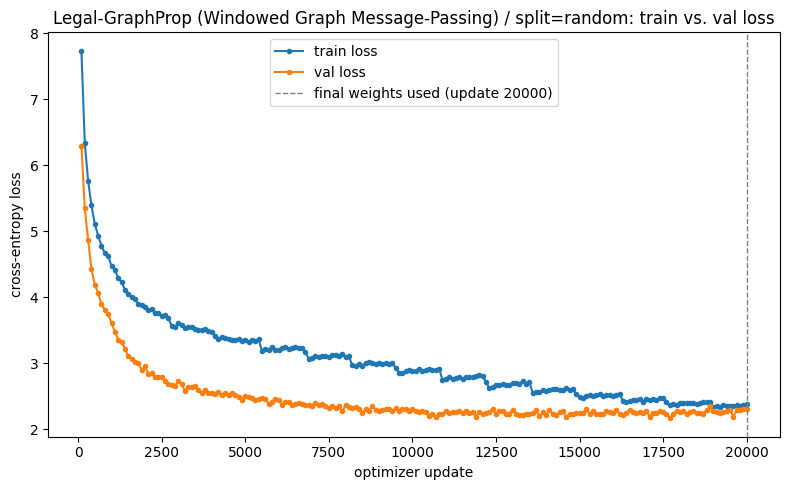

saved: /kaggle/working/loss_curve_legal_graphprop_random.png
final train_loss=2.3860  final val_loss=2.3078  gap=-0.0782


In [13]:
# Plot training vs validation loss
phase_marker(11, "Plotting training vs. validation loss")
if len(loss_history) < 2:
    print("fewer than 2 validation checks recorded -- not enough points for a useful plot "
          "(this happens if STEPS_THIS_SPLIT < Settings.EVAL_EVERY). Skipping.")
else:
    import matplotlib.pyplot as plt
    steps_axis = [h["step"] for h in loss_history]
    train_curve = [h["train_loss"] for h in loss_history]
    val_curve = [h["val_loss"] for h in loss_history]
    best_step = steps_axis[-1]

    plt.figure(figsize=(8, 5))
    plt.plot(steps_axis, train_curve, label="train loss", marker="o", markersize=3)
    plt.plot(steps_axis, val_curve, label="val loss", marker="o", markersize=3)
    plt.axvline(best_step, color="gray", linestyle="--", linewidth=1,
                label=f"final weights used (update {best_step})")
    plt.xlabel("optimizer update")
    plt.ylabel("cross-entropy loss")
    plt.title(f"{ARCH_NAME} / split={SPLIT_KEY}: train vs. val loss")
    plt.legend()
    plt.tight_layout()
    plot_path = os.path.join(WORK_DIR, f"loss_curve_{ARCH_SLUG}.png")
    plt.savefig(plot_path, dpi=110)
    plt.show()
    print(f"saved: {plot_path}")

    gap = val_curve[-1] - train_curve[-1]
    print(f"final train_loss={train_curve[-1]:.4f}  final val_loss={val_curve[-1]:.4f}  gap={gap:.4f}")
    if gap > 0.5:
        print("  a large, still-growing gap here (even after early stopping) suggests the model "
              "is still prone to overfitting at this data/step scale -- consider more data, more "
              "dropout, or stronger weight decay next time.")

In [14]:
# Save the best model and its score
phase_marker(12, "Saving checkpoint and score record")
metric_used = "bertscore_f1" if val_metrics["bertscore_f1"] is not None else "rouge_l_f1"
metric_value = val_metrics["bertscore_f1"] if val_metrics["bertscore_f1"] is not None else val_metrics["rouge_l_f1"]

ckpt_path = os.path.join(CKPT_DIR, f"{ARCH_SLUG}_final_{split_name}.pt")
torch.save(best_state, ckpt_path)
ckpt_path_root = os.path.join(WORK_DIR, f"{ARCH_SLUG}_final_{split_name}.pt")
torch.save(best_state, ckpt_path_root)
print(f"saved: {ckpt_path}")
print(f"saved (also at {WORK_DIR} root): {ckpt_path_root}")

score_record = {
    "architecture": ARCH_NAME, "arch_slug": ARCH_SLUG, "split_key": SPLIT_KEY,
    "split_name": split_name, "metric_name": metric_used, "metric_value": metric_value,
    "final_train_loss": val_metrics["final_train_loss"], "best_val_loss": val_metrics["best_val_loss"],
    "stopped_early": val_metrics["stopped_early"], "val_n": val_metrics["n"],
    "train_n": len(train_items), "dropout": Settings.DROPOUT,
}
score_path = os.path.join(WORK_DIR, f"score_{ARCH_SLUG}.json")
with open(score_path, "w", encoding="utf-8") as f:
    json.dump(score_record, f, indent=2)
print(f"score record: {score_path}")
print(f"\nValidation {metric_used} for this split is saved in the score record; the matching "
      f"checkpoint is used for the test predictions.")

best_model = enable_multi_gpu(build_model().to(device), purpose="gen")
strip_replica(best_model).load_state_dict(best_state)
release_memory()


[GraphProp | 12/13] Saving checkpoint and score record
saved: /kaggle/working/checkpoints/legal_graphprop_random_final_random_90_10.pt
saved (also at /kaggle/working root): /kaggle/working/legal_graphprop_random_final_random_90_10.pt
score record: /kaggle/working/score_legal_graphprop_random.json

Validation bertscore_f1 for this split is saved in the score record; the matching checkpoint is used for the test predictions.
    multi-GPU: using 2 GPUs via nn.DataParallel (for gen)


In [15]:
# Generate test predictions and make submission zip
phase_marker(13, "Generating official test predictions + packaging submission")
predictions = {}
if len(official_prompts) > 0:
    gen_ids, gen_prompts = official_ids, official_prompts
    if getattr(Settings, "SMOKE_TEST", False):
        cap = getattr(Settings, "_SMOKE_GEN_CAP", len(official_prompts))
        gen_ids, gen_prompts = official_ids[:cap], official_prompts[:cap]
        print(f"SMOKE_TEST=True -- generating only {len(gen_prompts)}/{len(official_prompts)} "
              f"official test prompts (set Settings.SMOKE_TEST=False for the real full-coverage run).")
    continuations = generate_with_min_length_retry(best_model, tokenizer, gen_prompts,
                                                    batch_size=Settings.GEN_BATCH_SIZE, desc="official test set")
    for tid, cont in zip(gen_ids, continuations):
        predictions[str(tid)] = {"text": cont}
    print(f"generated {len(predictions)} predictions "
          f"(expected: every official test ID, doc 6.4 -- unless SMOKE_TEST capped it above)")
else:
    print("no test prompts available -- cannot generate predictions.")

if predictions:
    pred_path = os.path.join(OUT_DIR, "prediction.json")
    with open(pred_path, "w", encoding="utf-8") as f:
        json.dump(predictions, f, indent=2, ensure_ascii=False)
    pred_path_root = os.path.join(WORK_DIR, "prediction.json")
    with open(pred_path_root, "w", encoding="utf-8") as f:
        json.dump(predictions, f, indent=2, ensure_ascii=False)

    zip_path = os.path.join(OUT_DIR, f"submission_{ARCH_SLUG}.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")
    zip_path_root = os.path.join(WORK_DIR, f"submission_{ARCH_SLUG}.zip")
    with zipfile.ZipFile(zip_path_root, "w", zipfile.ZIP_DEFLATED) as zf:
        zf.write(pred_path, arcname="prediction.json")
    print(f"submission: {zip_path_root}  (upload to Codabench ONLY if this split wins)")
    with zipfile.ZipFile(zip_path_root) as zf:
        print("zip contents:", [i.filename for i in zf.filelist])

print("\n" + "=" * 78)
print(f"SUMMARY -- {ARCH_NAME} / split={SPLIT_KEY}")
print("=" * 78)
print(f"trained split       : {split_name}")
print(f"parameters          : {n_params:,}")
print(f"corpus              : {len(corpus)} docs, by source {dict(source_counts)}")
print(f"local {metric_used:<15}: {metric_value:.4f}")
print(f"test coverage       : {len(predictions)} / {len(official_prompts)}")
print(f"\nfiles under {WORK_DIR}:")
print(f"  - {ckpt_path_root}")
print(f"  - {score_path}")
print(f"  - {pred_path_root}")
print(f"  - {zip_path_root}")
print("\nDone. The test predictions are packaged in submission.zip and the "
      "validation score is saved in the score record "
      "(see above).")


[GraphProp | 13/13] Generating official test predictions + packaging submission


official test set:   0%|          | 0/32 [00:00<?, ?batch/s]

generated 1000 predictions (expected: every official test ID, doc 6.4 -- unless SMOKE_TEST capped it above)
submission: /kaggle/working/submission_legal_graphprop_random.zip  (upload to Codabench ONLY if this split wins)
zip contents: ['prediction.json']

SUMMARY -- Legal-GraphProp (Windowed Graph Message-Passing) / split=random
trained split       : random_90_10
parameters          : 210,183,816
corpus              : 24000 docs, by source {'acts': 6000, 'high_courts': 6000, 'supreme_court': 6000, 'tribunals': 6000}
local bertscore_f1   : 0.8363
test coverage       : 1000 / 1000

files under /kaggle/working:
  - /kaggle/working/legal_graphprop_random_final_random_90_10.pt
  - /kaggle/working/score_legal_graphprop_random.json
  - /kaggle/working/prediction.json
  - /kaggle/working/submission_legal_graphprop_random.zip

Done. The test predictions are packaged in submission.zip and the validation score is saved in the score record (see above).
